# Python · NestedKriging — aggregations, large n

**Idea.** NestedKriging splits a large design into groups and aggregates their
predictions; how far is it from the exact predictor as the number of groups grows,
and which aggregation is closest?

**Reference.** The exact predictor at the same θ (limit: 1 group), and the exact
fit.

**Tags.** class: NestedKriging · aggregation: NK, PoE, gPoE, BCM, rBCM ·
topic: large n

`NestedKriging` partitions the design into groups, fits one `Kriging`
sub-model per group (common hyperparameters), and aggregates the sub-model
predictions: `NK` (nested kriging: kriging of the sub-predictors, a proper
kriging predictor), or the products of experts `PoE`, `gPoE`, `BCM`, `rBCM`
(cheaper, variances not fully consistent).

Problems: as in `large-n_Kriging-vecchia-nystrom_python.ipynb`, Hartmann 3
and the OTL circuit with n = 1500 (exact fit as reference) and n = 5000; then
every aggregation on Branin.

Checks:
* **limit and asymptotic behaviour** at fixed θ (Hartmann 3, n = 300): with one
  group, `NK` *is* the exact kriging predictor; the gap to the exact predictor
  as the number of groups grows, against the fit and prediction cost;
* accuracy close to the exact fit (warn-level gap, error-level floor), and
  faster than the exact fit at n = 1500 (warn-level);
* `NK` interpolates the data (it is a proper kriging predictor); the PoE family
  does not need to; all stdev ≥ 0;
* `NK` with a non-constant trend is rejected (simple-kriging theory).

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

suite = gallery.Suite("aggregations-large-n_NestedKriging_python")
print("pylibkriging", compat.version())
if not compat.has("NestedKriging"):
    suite.check_skip("NestedKriging", "not available in this pylibkriging")


def pred(k, X, **kw):
    m, s, *_ = k.predict(X, return_stdev=True, **kw)
    return np.ravel(m), np.ravel(s)


def timed(f):
    t0 = time.time()
    out = f()
    return out, time.time() - t0

pylibkriging 1.2.2


## From one group (the exact predictor) to many, at fixed θ

Hartmann 3, n = 300, θ of the exact fit kept fixed in every sub-model: the gap
is that of the aggregation alone. RMS gap of the predicted mean to the exact
predictor on 500 test points, relative to its standard deviation, and fit time.

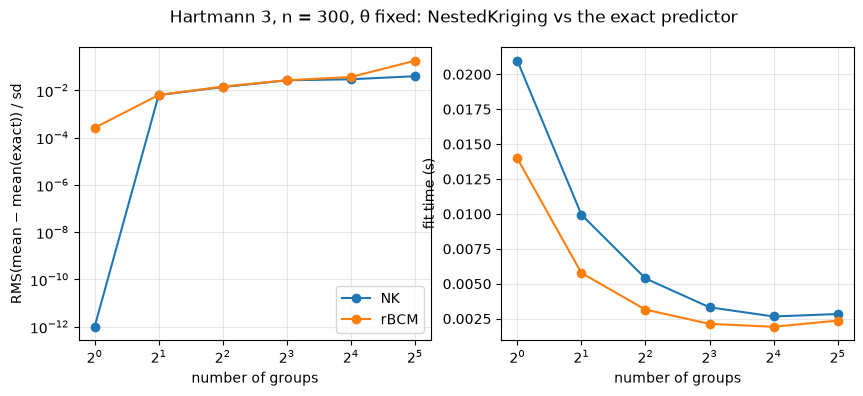

,aggregation,groups,time_s,mean_gap,q2
0,NK,1,0.02097,0.00000,0.99996
1,NK,2,0.00995,0.00638,0.99992
2,NK,4,0.00538,0.01386,0.99979
3,NK,8,0.00332,0.02672,0.99929
4,NK,16,0.00266,0.02964,0.99911
5,NK,32,0.00284,0.04000,0.99839
6,rBCM,1,0.01397,0.00026,0.99996
7,rBCM,2,0.00577,0.00640,0.99993
8,rBCM,4,0.00315,0.01452,0.99978
9,rBCM,8,0.00213,0.02696,0.99927


In [3]:
if compat.has("NestedKriging"):
    tf = TESTS["hartmann3"]
    X, y, Xt, yt = design.dataset(tf, 300, n_test=500, seed=54)
    theta = np.asarray(lk.Kriging(y, X, "matern5_2").theta()).reshape(1, -1)
    fixed = {"theta": theta, "is_theta_estim": False}
    m_e = pred(lk.Kriging(y, X, "matern5_2", optim="none", parameters=fixed), Xt)[0]
    rows = []
    for agg in ["NK", "rBCM"]:
        for g in [1, 2, 4, 8, 16, 32]:
            with suite.check_runs(f"nested {agg}, {g} groups, fixed theta: fit + predict"):
                k, t = timed(lambda: lk.NestedKriging(y, X, "matern5_2", nb_groups=g, aggregation=agg, seed=1,
                                                      optim="none", parameters=fixed))
                m = pred(k, Xt)[0]
                rows.append(dict(aggregation=agg, groups=g, time_s=t,
                                 mean_gap=np.sqrt(np.mean((m - m_e) ** 2)) / np.std(m_e),
                                 q2=metrics.q2(yt, m)))
    conv = pd.DataFrame(rows)
    nk = conv[conv["aggregation"] == "NK"]
    suite.check_less("nested NK, 1 group == exact predictor (RMS gap / sd)", nk["mean_gap"].iloc[0], 1e-6)
    suite.check_less("nested NK, 32 groups: RMS gap to the exact predictor / sd", nk["mean_gap"].iloc[-1], 0.1,
               severity="warn")
    rb = conv[conv["aggregation"] == "rBCM"]
    suite.check_true("nested NK closer to the exact predictor than rBCM (2 to 32 groups)",
               bool(np.all(nk["mean_gap"].to_numpy()[1:] <= rb["mean_gap"].to_numpy()[1:])), severity="warn")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for agg, g in conv.groupby("aggregation"):
        axes[0].semilogy(g["groups"], np.maximum(g["mean_gap"], 1e-12), "o-", label=agg)
        axes[1].plot(g["groups"], g["time_s"], "o-", label=agg)
    axes[0].set_ylabel("RMS(mean − mean(exact)) / sd"); axes[1].set_ylabel("fit time (s)")
    for ax in axes:
        ax.set_xscale("log", base=2); ax.set_xlabel("number of groups"); ax.grid(True, which="both", alpha=.3)
    axes[0].legend(); fig.suptitle("Hartmann 3, n = 300, θ fixed: NestedKriging vs the exact predictor"); plt.show()
    display(conv.round(5))

## Accuracy and cost against the exact fit

In [4]:
CASES = {"hartmann3": (1500, 5000), "otl_circuit": (1500, 5000)}
FLOORS = {"hartmann3": 0.98, "otl_circuit": 0.99}
if compat.has("NestedKriging"):
    for fname, (n_mid, n_big) in CASES.items():
        tf = TESTS[fname]
        X, y, Xt, yt = design.dataset(tf, n_big, n_test=2000, seed=52)
        ke, t_exact = timed(lambda: lk.Kriging(y[:n_mid], X[:n_mid], "matern5_2"))
        res_e = metrics.all_metrics(yt, *pred(ke, Xt))
        suite.metric(f"{fname}/n={n_mid}", "exact", fit_s=t_exact, **res_e)
        for agg in ["NK", "rBCM"]:
            label = f"nested {agg} (20 groups)"
            for n in (n_mid, n_big):
                case = f"{fname}/n={n}"
                with suite.check_runs(f"{case}/{label}: fit + predict"):
                    k, t = timed(lambda: lk.NestedKriging(y[:n], X[:n], "matern5_2", nb_groups=20, aggregation=agg,
                                                          seed=1))
                    m, s = pred(k, Xt)
                    suite.check_finite(f"{case}/{label}: finite predictions", m)
                    res = metrics.all_metrics(yt, m, s)
                    suite.metric(case, label, fit_s=t, **res)
                    suite.check_greater(f"{case}/{label}: Q2", res["q2"], FLOORS[fname] - 0.05)
                    if n == n_mid:
                        suite.check_greater(f"{case}/{label}: Q2 - Q2(exact)", res["q2"] - res_e["q2"], -0.02,
                                      severity="warn")
                        suite.check_less(f"{case}/{label}: fit time / exact fit time", t / t_exact, 1.0, severity="warn")
    display(suite.table().round(4))

metric                                       fit_s    rmse   q2    nlpd  \
case               package                                                
hartmann3/n=1500   exact                    3.7774  0.0003  1.0 -6.9218   
                   nested NK (20 groups)    0.1276  0.0030  1.0 -4.8595   
                   nested rBCM (20 groups)  0.1177  0.0030  1.0 -4.5018   
hartmann3/n=5000   nested NK (20 groups)    1.3568  0.0002  1.0 -7.4520   
                   nested rBCM (20 groups)  1.2419  0.0002  1.0 -7.1921   
otl_circuit/n=1500 exact                    5.3262  0.0001  1.0 -8.2231   
                   nested NK (20 groups)    0.1686  0.0023  1.0 -4.9055   
                   nested rBCM (20 groups)  0.1581  0.0029  1.0 -2.5553   
otl_circuit/n=5000 nested NK (20 groups)    1.9063  0.0003  1.0 -7.2126   
                   nested rBCM (20 groups)  1.7965  0.0003  1.0 -4.3985   

metric                                      coverage95    crps  
case               package                                      
hartmann3/n=1500   exact                        0.9970  0.0001  
                   nested NK (20 groups)        0.9800  0.0012  
                   nested rBCM (20 groups)      0.8115  0.0012  
hartmann3/n=5000   nested NK (20 groups)        0.9830  0.0001  
                   nested rBCM (20 groups)      0.8240  0.0001  
otl_circuit/n=1500 exact                        0.9800  0.0000  
                   nested NK (20 groups)        0.9545  0.0011  
                   nested rBCM (20 groups)      0.6115  0.0015  
otl_circuit/n=5000 nested NK (20 groups)        0.9470  0.0001  
                   nested rBCM (20 groups)      0.5615  0.0001

## `NestedKriging` aggregations: interpolation and variance

In [5]:
if compat.has("NestedKriging"):
    tf = TESTS["branin"]
    X, y, Xt, yt = design.dataset(tf, 200, n_test=500, seed=53)
    for agg in ["NK", "PoE", "gPoE", "BCM", "rBCM"]:
        with suite.check_runs(f"nested {agg}: fit"):
            k = lk.NestedKriging(y, X, "matern5_2", nb_groups=8, aggregation=agg, seed=2)
            m, s = (np.ravel(a) for a in k.predict(Xt, return_stdev=True)[:2])
            suite.check_true(f"nested {agg}: stdev >= 0", np.all(s >= 0))
            suite.metric("branin/nested", agg, **metrics.all_metrics(yt, m, s))
            if agg == "NK":
                mX = np.ravel(k.predict(X, return_stdev=True)[0])
                suite.check_less("nested NK: interpolates (max |m(X)-y| / sd(y))", np.max(np.abs(mX - y)) / np.std(y),
                           1e-4)
    display(suite.table().loc["branin/nested"].round(4))
    suite.check_raises("nested NK with a linear trend is rejected",
                 lambda: lk.NestedKriging(y, X, "matern5_2", nb_groups=4, aggregation="NK", regmodel="linear"),
                 severity="warn")

metric,fit_s,rmse,q2,nlpd,coverage95,crps
package,,,,,,
NK,NaN,0.0351,1.0,7.832870e+15,0.988,0.0236
PoE,NaN,0.0365,1.0,-1.698400e+00,1.000,0.0241
gPoE,NaN,0.0365,1.0,-6.776000e-01,1.000,0.0628
BCM,NaN,0.0365,1.0,-1.698400e+00,1.000,0.0241
rBCM,NaN,0.0363,1.0,-2.639900e+00,0.994,0.0129


## save / load, pickle, copy

On Hartmann 3 (n = 40): a model saved and loaded back (class-specific and
generic `pylibkriging.load`), pickled, or deep-copied predicts exactly as the
original.

In [6]:
if compat.has("NestedKriging"):
    X, y, Xt, yt = design.dataset(TESTS["hartmann3"], 40, n_test=100, seed=61)
    with suite.check_runs("NestedKriging: fit (persistence)"):
        gallery.persistence.check(suite, "NestedKriging", lk.NestedKriging(y, X, "matern5_2", nb_groups=4, seed=1), Xt, pred)

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/aggregations-large-n_NestedKriging_python.checks.csv` and `.metrics.csv`.

In [7]:
suite.summary()

metric                                       fit_s    rmse   q2          nlpd  \
case               package                                                      
hartmann3/n=1500   exact                    3.7774  0.0003  1.0 -6.921800e+00   
                   nested NK (20 groups)    0.1276  0.0030  1.0 -4.859500e+00   
                   nested rBCM (20 groups)  0.1177  0.0030  1.0 -4.501800e+00   
hartmann3/n=5000   nested NK (20 groups)    1.3568  0.0002  1.0 -7.452000e+00   
                   nested rBCM (20 groups)  1.2419  0.0002  1.0 -7.192100e+00   
otl_circuit/n=1500 exact                    5.3262  0.0001  1.0 -8.223100e+00   
                   nested NK (20 groups)    0.1686  0.0023  1.0 -4.905500e+00   
                   nested rBCM (20 groups)  0.1581  0.0029  1.0 -2.555300e+00   
otl_circuit/n=5000 nested NK (20 groups)    1.9063  0.0003  1.0 -7.212600e+00   
                   nested rBCM (20 groups)  1.7965  0.0003  1.0 -4.398500e+00   
branin/nested      NK                          NaN  0.0351  1.0  7.832870e+15   
                   PoE                         NaN  0.0365  1.0 -1.698400e+00   
                   gPoE                        NaN  0.0365  1.0 -6.776000e-01   
                   BCM                         NaN  0.0365  1.0 -1.698400e+00   
                   rBCM                        NaN  0.0363  1.0 -2.639900e+00   

metric                                      coverage95    crps  
case               package                                      
hartmann3/n=1500   exact                        0.9970  0.0001  
                   nested NK (20 groups)        0.9800  0.0012  
                   nested rBCM (20 groups)      0.8115  0.0012  
hartmann3/n=5000   nested NK (20 groups)        0.9830  0.0001  
                   nested rBCM (20 groups)      0.8240  0.0001  
otl_circuit/n=1500 exact                        0.9800  0.0000  
                   nested NK (20 groups)        0.9545  0.0011  
                   nested rBCM (20 groups)      0.6115  0.0015  
otl_circuit/n=5000 nested NK (20 groups)        0.9470  0.0001  
                   nested rBCM (20 groups)      0.5615  0.0001  
branin/nested      NK                           0.9880  0.0236  
                   PoE                          1.0000  0.0241  
                   gPoE                         1.0000  0.0628  
                   BCM                          1.0000  0.0241  
                   rBCM                         0.9940  0.0129

71 checks: PASS 71, FAIL 0, WARN 0, KNOWN 0, SKIP 0


In [8]:
suite.finalize()

aggregations-large-n_NestedKriging_python: PASS 71, FAIL 0, WARN 0, KNOWN 0, SKIP 0


{'PASS': 71, 'FAIL': 0, 'WARN': 0, 'KNOWN': 0, 'SKIP': 0}